# Module 1 - Exploratory data analysis

This notebook satisfies the Week 1 Definition of Done: a short EDA notebook with at least three visualisations. Every number and plot below is computed from `data/raw/patient_records.csv`; the raw file is never modified.

The three required views are the numeric feature distributions, a correlation heatmap, and the target class balance.

In [1]:
from src import config
from src.data import preprocessing
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
raw = preprocessing.load_raw_records(config.RAW_PATIENT_CSV)
print(f'rows={len(raw)}  columns={len(raw.columns)}')
print(raw.dtypes.to_string())
missing = raw.isna().sum()
print('\nMissing cells (loader semantics):')
print(missing[missing > 0].to_string())

rows=500  columns=7
Patient_ID                  object
Age                          int64
Biomarker_Level            float64
Pre_Existing_Conditions      int64
Vaccine_Dose_mcg           float64
Prior_Reaction_History      object
Reaction_Score               int64

Missing cells (loader semantics):
Biomarker_Level           20
Prior_Reaction_History    17


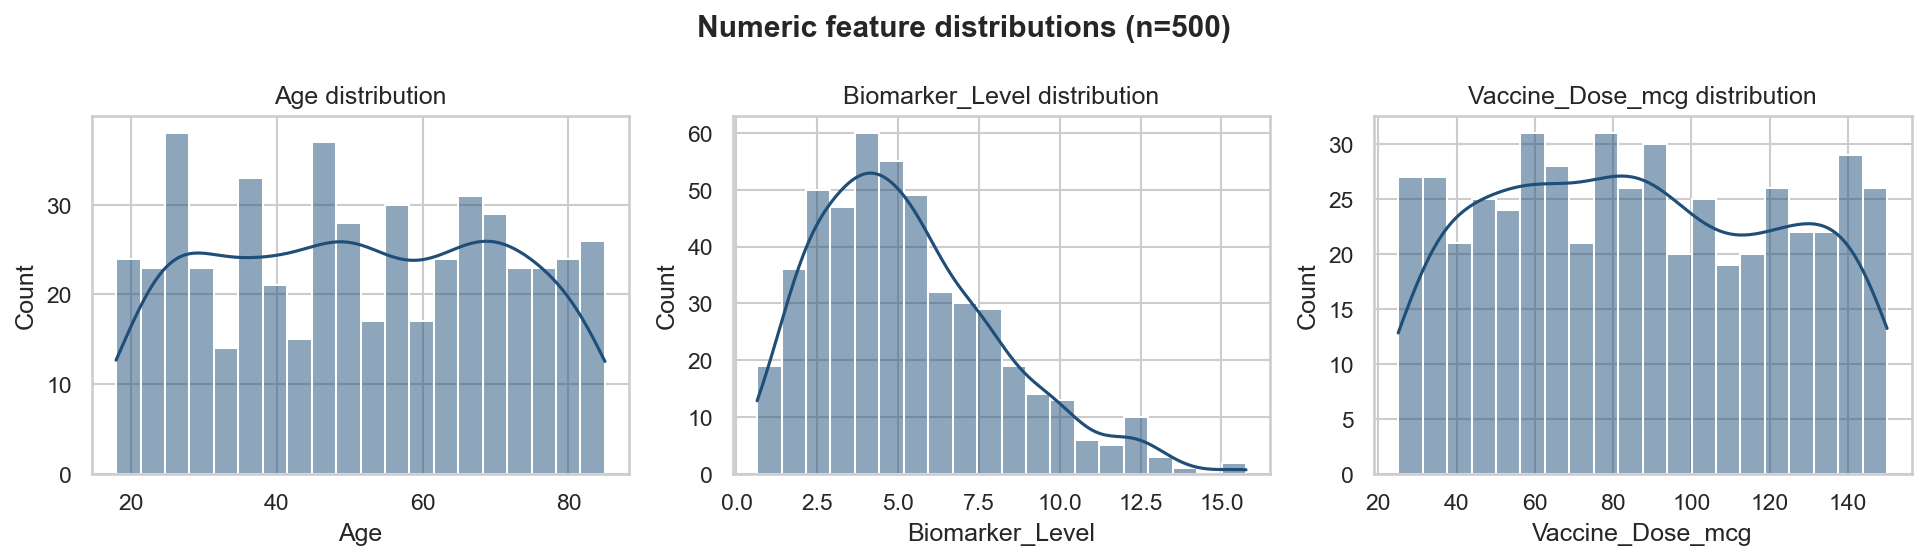

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, column in zip(axes, config.NUMERIC_COLS):
    sns.histplot(raw[column].dropna(), bins=20, kde=True, ax=ax, color='#1F4E79')
    ax.set_title(f'{column} distribution')
    ax.set_xlabel(column)
fig.suptitle('Numeric feature distributions (n=500)', fontweight='600')
fig.tight_layout()

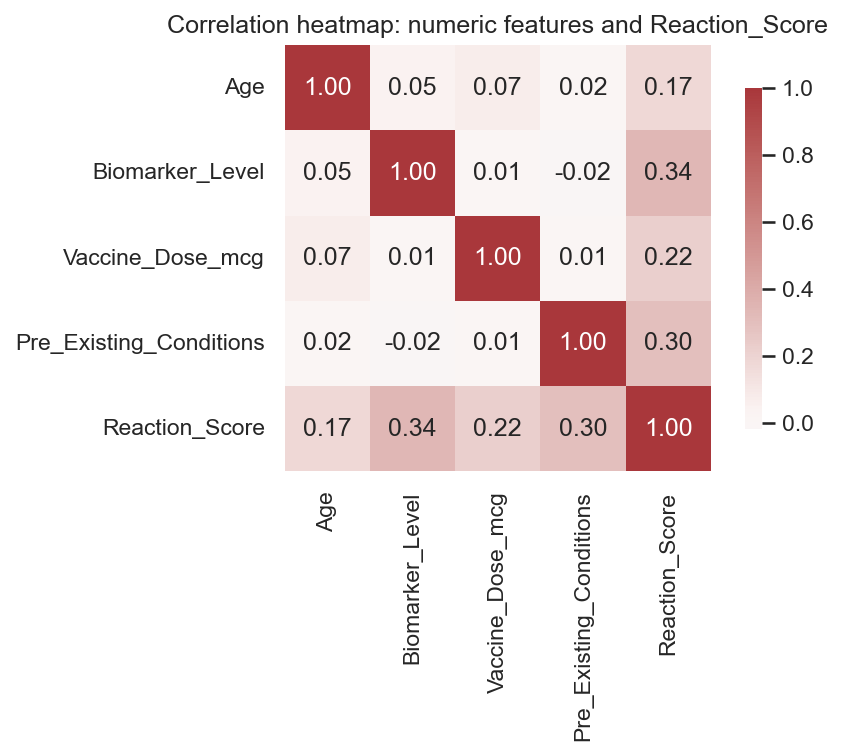

In [3]:
numeric = raw[list(config.NUMERIC_COLS) + [config.COUNT_COL, config.TARGET_COL]].copy()
numeric = numeric.fillna(numeric.median(numeric_only=True))
correlation = numeric.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(6.6, 5.2))
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='vlag', center=0,
            square=True, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Correlation heatmap: numeric features and Reaction_Score')
fig.tight_layout()

Reaction_Score
0    255
1    245


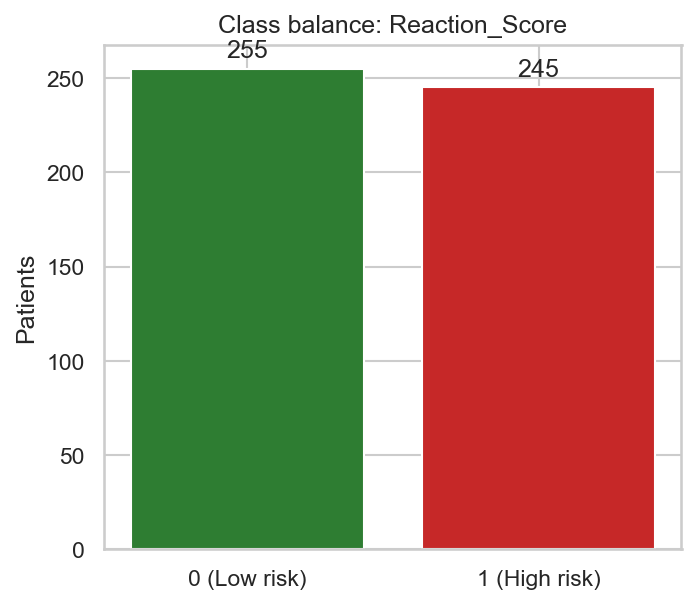

In [4]:
counts = raw[config.TARGET_COL].value_counts().sort_index()
labels = [f'{int(value)} ({"Low risk" if int(value) == 0 else "High risk"})'
          for value in counts.index]
fig, ax = plt.subplots(figsize=(4.8, 4.2))
bars = ax.bar(labels, counts.values, color=['#2E7D32', '#C62828'])
ax.bar_label(bars, padding=3)
ax.set_ylabel('Patients')
ax.set_title('Class balance: Reaction_Score')
fig.tight_layout()
print(counts.to_string())

## What the data shows

- **Rows:** 500; **columns:** 7.
- **Target balance:** class 0 = 255, class 1 = 245. The split is close to even, so accuracy is not dominated by one class.
- **Missing cells:** Biomarker_Level = 20, Prior_Reaction_History = 17. The literal string `None` is a real category, not a missing value: it appears in 291 rows. The loader therefore uses `keep_default_na=False` with an explicit empty-string NA list.
- **Correlation:** the heatmap shows no feature with a strong linear relationship to Reaction_Score, which is consistent with the modest held-out ROC-AUC reported in the README. The classifier is a screening signal, not a deterministic rule.
